---
title: "Relativity and Electrodynamics — Level 2"
short_title: "10 Relativity & Electrodynamics"
numbering:
  heading_2: true
  equation: true
---

# Relativity and Electrodynamics

:::{seealso} Math for this topic
- [M6: Linear algebra](../../level2-book/math/06-linear-algebra.ipynb)
- [M7: Legendre transforms, phase portraits and hyperbolic functions](../../level2-book/math/07-legendre-phase-hyperbolic.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 39 (approx.) | Not covered for fields; start at Level 2 |
| **2** | **Griffiths, ch. 12** | **Field transformations, the field tensor** |
| 3 | Jackson, ch. 11–12 | Covariant formulation, Lorentz force, invariants |

The new skill at this level: seeing E and B as two faces of one tensor, so that what one observer calls magnetic another calls electric

Math for this topic: mechanics M6 (matrices, tensors) and M7 (hyperbolic functions); mechanics topic 12 (special relativity) comes first.
:::

Workbook example ladder: charge moving past a wire → E and B in different frames → the field tensor and its invariants. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## Magnetism as a Relativistic Effect

A long neutral wire carries current: positive charges at rest, negative charges drifting with speed $u$, linear densities $+\lambda$ and $-\lambda$ in the lab, so the wire is neutral. A test charge $q$ moves parallel to the wire with speed $v$, at distance $s$.

**In the lab** the wire is neutral, so there is no electric force. The current $I = \lambda u$ produces $B = \mu_0I/(2\pi s)$, and the test charge feels a magnetic force $F = qvB$.

**In the test charge's rest frame** its velocity is zero, so there can be no magnetic force on it. The two line charges now move at different speeds, so they are length-contracted by different amounts, and the wire is **no longer neutral**. Working out the densities with the velocity-addition rule (mechanics topic 12) gives a net line charge, and its electric field produces exactly the force the lab observer called magnetic (transformed as a force should be).

The surprise is the scale: drift speeds in wires are millimeters per second, so the effect is of order $uv/c^2$, absurdly small, but the electric forces between the enormous charge densities in a wire are so large that this tiny imbalance is the entire magnetic force between currents. Magnetism is what relativity looks like when huge electric forces almost cancel.

In [2]:
# The wire argument, symbolically: net charge density seen by the moving test charge
lam, u, v, c_s = sp.symbols("lambda u v c", positive=True)
gam = lambda w: 1 / sp.sqrt(1 - w**2 / c_s**2)
lam0_minus = lam / gam(u)                     # proper density of the moving negative charges
u_rel = (u - v) / (1 - u * v / c_s**2)        # their speed in the test charge's frame
lam_plus = gam(v) * lam                       # positives (at rest in the lab) seen from the moving frame
lam_minus = gam(u_rel) * lam0_minus
net = sp.simplify(lam_plus - lam_minus)
print("net line charge in test-charge frame:", sp.simplify(net))
print("to first order in u v / c^2:", sp.simplify(sp.series(net.subs({u: sp.Symbol('e') * u, v: sp.Symbol('e') * v}), sp.Symbol('e'), 0, 3).removeO().subs(sp.Symbol('e'), 1)))

net line charge in test-charge frame: c*lambda/sqrt(c**2 - v**2) - lambda*sqrt(c**2 - u**2)/(c*sqrt(-c**2*(u - v)**2/(c**2 - u*v)**2 + 1))
to first order in u v / c^2: lambda*u*v/c**2


## How the Fields Transform

For a frame $\mathcal{S}'$ moving with velocity $\vec{v}$ relative to $\mathcal{S}$ (with $\gamma = 1/\sqrt{1 - v^2/c^2}$), the fields at the same event are related by

$$
\begin{aligned}
\vec{E}'_\parallel &= \vec{E}_\parallel, & \vec{E}'_\perp &= \gamma\left(\vec{E} + \vec{v}\times\vec{B}\right)_\perp, \\
\vec{B}'_\parallel &= \vec{B}_\parallel, & \vec{B}'_\perp &= \gamma\left(\vec{B} - \frac{1}{c^2}\vec{v}\times\vec{E}\right)_\perp ,
\end{aligned}
$$ (eq-field-transform)

where $\parallel$ and $\perp$ refer to the direction of $\vec{v}$. A pure electric field in one frame has a magnetic part in another, and the reverse. For $v\ll c$, $\vec{E}' \approx \vec{E} + \vec{v}\times\vec{B}$: the force on a charge at rest in $\mathcal{S}'$ is the Lorentz force computed in $\mathcal{S}$, as it must be.

### The field of a moving charge

Transforming the Coulomb field of a charge at rest gives the field of a charge moving at constant velocity. At the present position of the charge, at angle $\theta$ from the direction of motion,

$$
\vec{E} = \frac{q}{4\pi\epsilon_0}\frac{1 - \beta^2}{\left(1 - \beta^2\sin^2\theta\right)^{3/2}}\frac{\hat{R}}{R^2} .
$$

It still points radially from where the charge **is now** (not from a retarded position), but it is weakened ahead and behind and strengthened sideways, squashed into a pancake as $\beta\to1$. A magnetic field $\vec{B} = \frac{1}{c^2}\vec{v}\times\vec{E}$ circles the path.

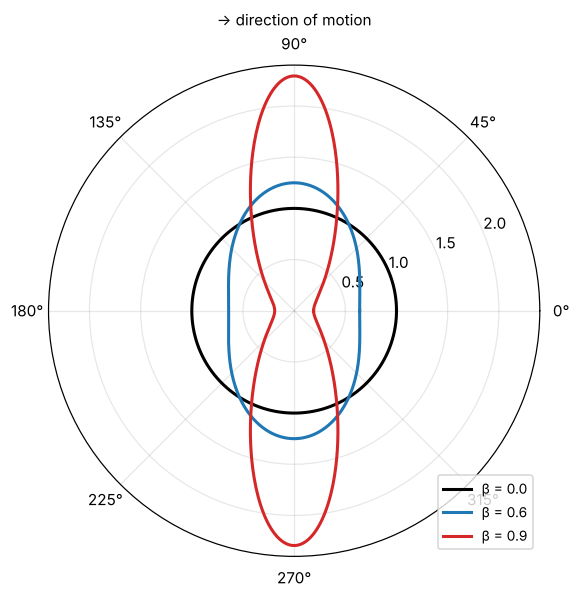

In [3]:
#| label: fig-moving-charge
#| caption: Field strength (times R², relative to Coulomb) around a charge moving to the right, versus direction, for β = 0, 0.6, 0.9. At β = 0.9 the field ahead and behind drops to 0.19 of Coulomb while the sideways field rises to 2.3: it concentrates in the plane perpendicular to the motion.
th = np.linspace(0, 2 * np.pi, 600)
fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(5.8, 5.8))
for beta, col in [(0.0, "k"), (0.6, "tab:blue"), (0.9, "tab:red")]:
    Erel = (1 - beta**2) / (1 - beta**2 * np.sin(th)**2)**1.5
    ax.plot(th, Erel, color=col, lw=2, label=f"β = {beta}")
ax.set_rmax(2.4); ax.set_theta_zero_location("E")
ax.legend(loc="lower right", fontsize=9); ax.set_title("→ direction of motion", fontsize=10)
plt.show()

## The Field Tensor

The transformations {eq}`eq-field-transform` look complicated because $\vec{E}$ and $\vec{B}$ are not four-vectors. Together they form an antisymmetric $4\times4$ tensor, with indices $(0, 1, 2, 3) = (ct, x, y, z)$:

$$
F^{\mu\nu} = \begin{pmatrix}
0 & E_x/c & E_y/c & E_z/c\\
-E_x/c & 0 & B_z & -B_y\\
-E_y/c & -B_z & 0 & B_x\\
-E_z/c & B_y & -B_x & 0
\end{pmatrix} .
$$

It transforms like any second-rank tensor (mechanics M6), with the Lorentz matrix $\Lambda$ in place of a rotation:

$$
F' = \Lambda\,F\,\Lambda^{\mathsf T} .
$$ (eq-tensor-transform-F)

That one line reproduces all of {eq}`eq-field-transform`. Two combinations are the same in every frame, the **invariants**:

$$
\vec{E}\cdot\vec{B}, \qquad E^2 - c^2B^2 .
$$

So if $\vec{E}\perp\vec{B}$ in one frame, it is so in all frames; and if $E > cB$ in one frame, there is a frame where $\vec{B} = \vec{0}$ (and conversely). A plane wave has both invariants zero: it is "light-like" in every frame.

In [4]:
# Boost the field tensor along x and recover eq-field-transform, then check the invariants
Ex, Ey, Ez, Bx, By, Bz = sp.symbols("E_x E_y E_z B_x B_y B_z", real=True)
c_s, beta = sp.symbols("c beta", positive=True)
F = sp.Matrix([[0, Ex / c_s, Ey / c_s, Ez / c_s],
               [-Ex / c_s, 0, Bz, -By],
               [-Ey / c_s, -Bz, 0, Bx],
               [-Ez / c_s, By, -Bx, 0]])
g = 1 / sp.sqrt(1 - beta**2)
L = sp.Matrix([[g, -g * beta, 0, 0], [-g * beta, g, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])
Fp = sp.simplify(L * F * L.T)
Ep = [sp.simplify(c_s * Fp[0, k]) for k in (1, 2, 3)]
Bp = [sp.simplify(Fp[2, 3]), sp.simplify(Fp[3, 1]), sp.simplify(Fp[1, 2])]
print("E' =", Ep)
print("B' =", Bp)
inv1 = lambda E, B: sp.simplify(sum(e * b_ for e, b_ in zip(E, B)))
inv2 = lambda E, B: sp.simplify(sum(e**2 for e in E) - c_s**2 * sum(b_**2 for b_ in B))
print("E.B invariant       :", sp.simplify(inv1(Ep, Bp) - inv1([Ex, Ey, Ez], [Bx, By, Bz])) == 0)
print("E^2 - c^2 B^2 invariant:", sp.simplify(inv2(Ep, Bp) - inv2([Ex, Ey, Ez], [Bx, By, Bz])) == 0)

E' = [E_x, (-B_z*beta*c + E_y)/sqrt(1 - beta**2), (B_y*beta*c + E_z)/sqrt(1 - beta**2)]
B' = [B_x, (B_y*c + E_z*beta)/(c*sqrt(1 - beta**2)), (B_z*c - E_y*beta)/(c*sqrt(1 - beta**2))]
E.B invariant       : True
E^2 - c^2 B^2 invariant: True


## Maxwell's Equations in Four-Vector Form

Charge density and current combine into the **four-current** $J^\mu = (c\rho, \vec{J})$, and the potentials into $A^\mu = (V/c, \vec{A})$. With $\partial_\mu = (\partial_{ct}, \nabla)$:

- **Charge conservation** is $\partial_\mu J^\mu = 0$, a statement that is manifestly the same in every frame.
- **Maxwell's equations** become two tensor equations:

$$
\partial_\mu F^{\mu\nu} = \mu_0J^\nu \quad\text{(Gauss and Ampère–Maxwell)}, \qquad
\partial_\lambda F_{\mu\nu} + \partial_\mu F_{\nu\lambda} + \partial_\nu F_{\lambda\mu} = 0 \quad\text{(no monopoles and Faraday)} .
$$

- The **Lorenz gauge** condition is $\partial_\mu A^\mu = 0$, and the potentials obey $\Box A^\mu = -\mu_0J^\mu$, where $\Box = \nabla^2 - \partial_t^2/c^2$ is the invariant wave operator.

Electrodynamics was already relativistic; Maxwell's equations needed no changes, only a notation that shows it. (Newtonian mechanics, by contrast, had to be rebuilt; that was mechanics topic 12.)

### Exercises

1. A uniform field $\vec{E} = E_0\hat{y}$ fills the lab (no $\vec{B}$). Find $\vec{E}'$ and $\vec{B}'$ in a frame moving at $\vec{v} = v\hat{x}$.
2. In some frame $\vec{E} = E_0\hat{x}$ and $\vec{B} = (E_0/2c)\hat{y}$. Is there a frame where the field is purely electric? Purely magnetic?
3. An electron beam (current $I$, radius $a$, speed $v$) is held together by its own magnetic attraction and pushed apart by its electric repulsion. Show that the net outward force on an electron at the edge is the electric force times $1/\gamma^2$.

:::{dropdown} Hints
1. $\vec{E}$ is perpendicular to $\vec{v}$; use {eq}`eq-field-transform`.
2. Compute both invariants.
3. Outside a uniform line charge $\lambda$, $E = \lambda/(2\pi\epsilon_0a)$; with $I = \lambda v$, $B = \mu_0I/(2\pi a)$. The magnetic force is $evB$.
:::

:::{dropdown} Answers
1. $\vec{E}' = \gamma E_0\hat{y}$, $\vec{B}' = -\gamma\dfrac{vE_0}{c^2}\hat{z}$.
2. $\vec{E}\cdot\vec{B} = 0$ and $E^2 - c^2B^2 = \tfrac34E_0^2 > 0$, so there is a frame with purely electric field (of magnitude $\tfrac{\sqrt3}{2}E_0$) and none with a purely magnetic field.
3. $F = eE - evB = eE(1 - v^2/c^2) = eE/\gamma^2$, using $\mu_0\epsilon_0 = 1/c^2$. Fast beams are nearly self-focusing, consistent with the beam's own rest frame, where only the electric repulsion exists and time runs slowly.
:::

## Summary

- The magnetic force between currents is the electric force from a relativistic charge imbalance, seen from another frame.
- $\vec{E}$ and $\vec{B}$ mix under boosts by {eq}`eq-field-transform`; a moving charge's field is squeezed perpendicular to its motion.
- Together they form the antisymmetric tensor $F^{\mu\nu}$, transforming as $\Lambda F\Lambda^{\mathsf T}$; $\vec{E}\cdot\vec{B}$ and $E^2 - c^2B^2$ are invariant.
- Charge conservation, Maxwell's equations and the Lorenz gauge take compact four-vector forms; electrodynamics was relativistic from the start.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.